In [13]:

# ==========================================
# 1. Import Libraries & Load API Key
# ==========================================

import requests
import pandas as pd
from google.colab import userdata

FRED_API_KEY = userdata.get('FRED_API_KEY')


# ==========================================
# 2. Function to Get FRED Data
# ==========================================

def get_fred_data(series_id, start_date="1959-01-01"):

    url = "https://api.stlouisfed.org/fred/series/observations"

    params = {
        "series_id": series_id,
        "api_key": FRED_API_KEY,
        "file_type": "json",
        "observation_start": start_date
    }

    response = requests.get(url, params=params)
    response.raise_for_status()

    data = response.json()

    df = pd.DataFrame(data["observations"])

    df = df[["date", "value"]].copy()

    df["date"] = pd.to_datetime(df["date"])
    df["value"] = pd.to_numeric(df["value"], errors="coerce")

    return df


# ==========================================
# 3. Get GS10 (10-Year Treasury Yield)
# ==========================================

df_gs10 = get_fred_data("GS10")

df_gs10.columns = ["Date", "10 Year Treasury Yield"]


# ==========================================
# 4. Get TB3MS (3-Month Treasury Yield)
# ==========================================

df_tb3ms = get_fred_data("TB3MS")

df_tb3ms.columns = ["Date", "3 Month Treasury Yield"]


# ==========================================
# 5. Calculate Bond Equivalent Yield (BEY)
# ==========================================

d = df_tb3ms["3 Month Treasury Yield"] / 100

df_tb3ms["3 Month Treasury Yield (Bond Equivalent Basis)"] = (
    (365 * d) / (360 - 91 * d)
) * 100


# ==========================================
# 6. Merge Treasury Yield Data
# ==========================================

df = pd.merge(
    df_gs10,
    df_tb3ms,
    on="Date",
    how="inner"
)

df = df.sort_values("Date").reset_index(drop=True)


# ==========================================
# 7. Calculate Yield Spread
# ==========================================

df["spread"] = (
    df["10 Year Treasury Yield"]
    - df["3 Month Treasury Yield (Bond Equivalent Basis)"]
)


# ==========================================
# 8. Get USRECQ (Quarterly NBER Recession)
# ==========================================

df_rec = get_fred_data("USRECQ")

df_rec.columns = ["Date", "NBER_Rec"]

df_rec = df_rec.sort_values("Date").reset_index(drop=True)


# ==========================================
# 9. Merge Quarterly Recession Data
#    into Monthly Data
# ==========================================

df = pd.merge_asof(
    df.sort_values("Date"),
    df_rec.sort_values("Date"),
    on="Date",
    direction="backward"
)

df = df.reset_index(drop=True)


# ==========================================
# 10. Display Final DataFrame
# ==========================================

display(df)

print("Number of observations:", len(df))
print("Start date:", df["Date"].min())
print("End date:", df["Date"].max())

print("\nMissing Values:")
print(df.isna().sum())

,Date,10 Year Treasury Yield,3 Month Treasury Yield,3 Month Treasury Yield (Bond Equivalent Basis),spread,NBER_Rec
0,1959-01-01,4.02,2.82,2.879694,1.140306,0
1,1959-02-01,3.96,2.70,2.756312,1.203688,0
2,1959-03-01,3.99,2.80,2.859125,1.130875,0
3,1959-04-01,4.12,2.95,3.013443,1.106557,0
4,1959-05-01,4.31,2.84,2.900265,1.409735,0
...,...,...,...,...,...,...
808,2026-05-01,4.48,3.60,3.683520,0.796480,0
809,2026-06-01,4.47,3.66,3.745485,0.724515,0
810,2026-07-01,4.60,3.73,3.817802,0.782198,0
811,2026-08-01,4.68,3.72,3.807470,0.872530,0


Number of observations: 813
Start date: 1959-01-01 00:00:00
End date: 2026-09-01 00:00:00

Missing Values:
Date                                              0
10 Year Treasury Yield                            0
3 Month Treasury Yield                            0
3 Month Treasury Yield (Bond Equivalent Basis)    0
spread                                            0
NBER_Rec                                          0
dtype: int64


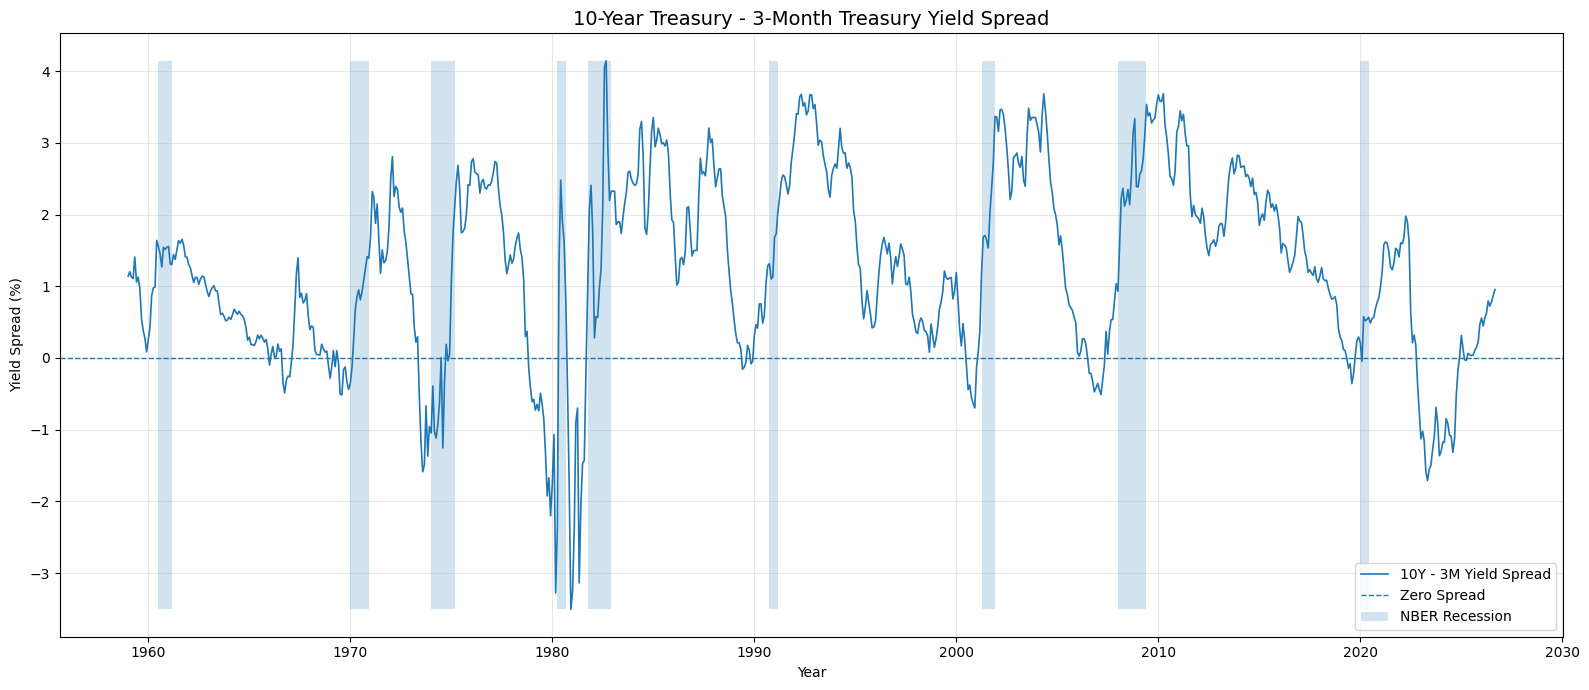

In [14]:
import matplotlib.pyplot as plt

# สร้าง Figure
fig, ax = plt.subplots(figsize=(16, 7))

# Plot Spread
ax.plot(
    df["Date"],
    df["spread"],
    label="10Y - 3M Yield Spread",
    linewidth=1.2
)

# เส้นศูนย์ (Zero Line)
ax.axhline(
    y=0,
    linestyle="--",
    linewidth=1,
    label="Zero Spread"
)

# Highlight Recession Periods
ax.fill_between(
    df["Date"],
    df["spread"].min(),
    df["spread"].max(),
    where=(df["NBER_Rec"] == 1),
    alpha=0.2,
    label="NBER Recession"
)

# Chart Title and Labels
ax.set_title(
    "10-Year Treasury - 3-Month Treasury Yield Spread",
    fontsize=14
)

ax.set_xlabel("Year")
ax.set_ylabel("Yield Spread (%)")

# Grid and Legend
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()